# CardioRitmo · Tamizaje de latidos anormales
Cuaderno de desarrollo (DEV). Objetivo del cliente, en la prueba y con umbral 0.5:
sensibilidad ≥ 95 %, especificidad ≥ 95 % y modelo con ≤ 20,000 parámetros.

In [ ]:
%pip install tensorflow scikit-learn pandas matplotlib
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ----------- ---------------------------- 2.4/8.2 MB 11.8 MB/s eta 0:00:01
   ---------------------- ----------------- 4.7/8.2 MB 11.8 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.2 MB 11.8 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.2 MB 11.8 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 8.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   -------- ------------------------------- 2.4/10.7 MB 11.8 MB/s eta 0:00:01
   ------------------ --------------------- 5.0/10.7 MB 11.8 MB/s eta 0:00:01
   --------------------------- ------------ 7.3/10.7 MB 11.9 MB/s eta 0:00:01
   ------------------------------------ --- 9.7/10.7 MB 11.8 MB/s eta 0:00:01
   ---------------------------------------  10.5/10.7 MB 11.8 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 8.9 MB/s eta 0:00:00
   -----


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


TensorFlow 2.21.0 | GPU: []


In [ ]:
ecg = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv", header=None)
X = ecg.iloc[:, :-1].to_numpy("float32")      # 140 puntos por latido
y = 1 - ecg.iloc[:, -1].to_numpy("int64")     # el archivo trae 1 = normal; aquí 1 = ANORMAL

# Prueba del cliente: 20 % estratificado. No se toca hasta el final.
X_resto, X_prueba, y_resto, y_prueba = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
print("Forma de X:", X.shape)
print("Valores faltantes:", int(np.isnan(X).sum()))
print(f"Rango de valores: {X.min():.2f} a {X.max():.2f}")
conteo = pd.Series(y).map({0: "normal", 1: "anormal"}).value_counts()
print("\nBalance de clases:")
print(pd.DataFrame({"latidos": conteo, "proporción": (conteo / len(y)).round(3)}))

Forma de X: (4998, 140)
Valores faltantes: 0
Rango de valores: -7.09 a 7.40

Balance de clases:
         latidos  proporción
normal      2919       0.584
anormal     2079       0.416


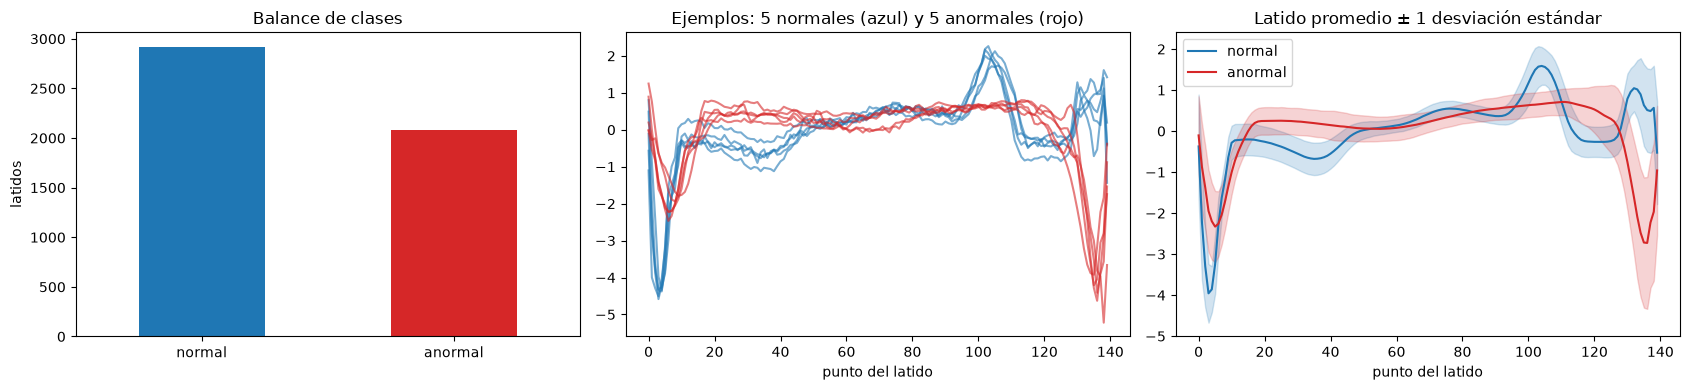

In [ ]:
t = np.arange(140)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

conteo.plot.bar(ax=ax[0], color=["tab:blue", "tab:red"])
ax[0].set_title("Balance de clases"); ax[0].set_ylabel("latidos"); ax[0].tick_params(axis="x", rotation=0)

for i in np.where(y == 0)[0][:5]:
    ax[1].plot(t, X[i], color="tab:blue", alpha=0.6)
for i in np.where(y == 1)[0][:5]:
    ax[1].plot(t, X[i], color="tab:red", alpha=0.6)
ax[1].set_title("Ejemplos: 5 normales (azul) y 5 anormales (rojo)"); ax[1].set_xlabel("punto del latido")

for c, color, nombre in [(0, "tab:blue", "normal"), (1, "tab:red", "anormal")]:
    m, s = X[y == c].mean(0), X[y == c].std(0)
    ax[2].plot(t, m, color=color, label=nombre)
    ax[2].fill_between(t, m - s, m + s, color=color, alpha=0.2)
ax[2].set_title("Latido promedio ± 1 desviación estándar"); ax[2].legend(); ax[2].set_xlabel("punto del latido")

plt.tight_layout(); plt.show()

In [ ]:
# La validación sale SOLO de X_resto; la prueba no se usa para nada hasta el final.
X_tr, X_val, y_tr, y_val = train_test_split(X_resto, y_resto, test_size=0.2, stratify=y_resto, random_state=SEED)

for nombre, (a, b) in {"entrenamiento": (X_tr, y_tr), "validación": (X_val, y_val), "prueba": (X_prueba, y_prueba)}.items():
    print(f"{nombre:>13}: {len(a):5d} latidos | {b.mean():.1%} anormales")

# Las redes convolucionales y recurrentes esperan (latidos, pasos de tiempo, canales)
X_tr3, X_val3, X_prueba3 = X_tr[..., None], X_val[..., None], X_prueba[..., None]

# Normalización: capa de Keras que aprende media y varianza SOLO con entrenamiento (adapt).
# Va dentro del modelo, así el modelo guardado ya incluye su preprocesamiento.
def capa_norm():
    norm = layers.Normalization(axis=None)
    norm.adapt(X_tr3)
    return norm

# Pesos por clase para que la red no favorezca a la clase mayoritaria (normal)
pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr)
class_weight = {0: pesos[0], 1: pesos[1]}
print("Pesos por clase:", {k: round(v, 3) for k, v in class_weight.items()})

entrenamiento:  3198 latidos | 41.6% anormales
   validación:   800 latidos | 41.6% anormales
       prueba:  1000 latidos | 41.6% anormales
Pesos por clase: {0: np.float64(0.856), 1: np.float64(1.202)}


In [ ]:
def metricas(y_true, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"sensibilidad": tp / (tp + fn),     # de los anormales, cuántos marca
            "especificidad": tn / (tn + fp),    # de los normales, cuántos NO marca
            "auc": roc_auc_score(y_true, prob)}

def n_param(modelo):  # solo parámetros entrenables
    return int(sum(np.prod(w.shape) for w in modelo.trainable_weights))

# Línea base: siempre dice "normal" (la clase más frecuente)
base = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
print("Línea base en validación:", {k: round(v, 3) for k, v in metricas(y_val, base.predict_proba(X_val)[:, 1]).items()})

Línea base en validación: {'sensibilidad': np.float64(0.0), 'especificidad': np.float64(1.0), 'auc': 0.5}


conv1d: 76 épocas | 5,857 parámetros entrenables
gru: 70 épocas | 3,393 parámetros entrenables
conjunto: 9,250 parámetros entrenables


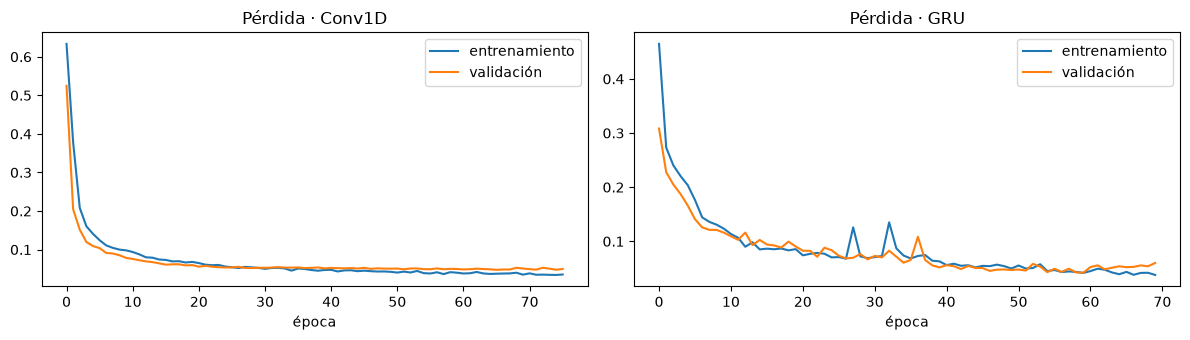

In [ ]:
def crear_conv1d():
    inp = keras.Input((140, 1))
    x = capa_norm()(inp)
    x = layers.Conv1D(16, 7, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(32, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(32, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out, name="conv1d")

def crear_gru():
    inp = keras.Input((140, 1))
    x = capa_norm()(inp)
    x = layers.GRU(32)(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out, name="gru")

def entrenar(modelo):
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                   metrics=[keras.metrics.AUC(name="auc")])
    hist = modelo.fit(X_tr3, y_tr, validation_data=(X_val3, y_val), epochs=100, batch_size=64,
                      class_weight=class_weight, verbose=0,
                      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                                               restore_best_weights=True)])
    print(f"{modelo.name}: {len(hist.history['loss'])} épocas | {n_param(modelo):,} parámetros entrenables")
    return hist

conv = crear_conv1d(); hist_conv = entrenar(conv)
gru = crear_gru();     hist_gru = entrenar(gru)

# Conjunto: promedia las probabilidades de los dos modelos ya entrenados (no se reentrena)
inp = keras.Input((140, 1))
conjunto = keras.Model(inp, layers.Average()([conv(inp), gru(inp)]), name="conjunto")
print(f"conjunto: {n_param(conjunto):,} parámetros entrenables")

# Curvas de aprendizaje
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, (nombre, h) in zip(ax, {"Conv1D": hist_conv, "GRU": hist_gru}.items()):
    a.plot(h.history["loss"], label="entrenamiento"); a.plot(h.history["val_loss"], label="validación")
    a.set_title(f"Pérdida · {nombre}"); a.set_xlabel("época"); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
modelos = {"Conv1D": conv, "GRU": gru, "Conjunto Conv1D+GRU": conjunto}
tipos = {"Línea base (siempre normal)": "linea base", "Conv1D": "convolucional",
         "GRU": "recurrente", "Conjunto Conv1D+GRU": "conjunto"}
parametros = {"Línea base (siempre normal)": 0, **{n: n_param(m) for n, m in modelos.items()}}

def predecir(m, X3):
    return m.predict(X3, verbose=0).ravel()

prob_val = {"Línea base (siempre normal)": base.predict_proba(X_val)[:, 1],
            **{n: predecir(m, X_val3) for n, m in modelos.items()}}

val_df = pd.DataFrame([{"modelo": n, "parametros": parametros[n], **metricas(y_val, p)} for n, p in prob_val.items()])
val_df["cumple"] = (val_df.sensibilidad >= 0.95) & (val_df.especificidad >= 0.95) & (val_df.parametros <= 20000)
val_df["peor_metrica"] = val_df[["sensibilidad", "especificidad"]].min(axis=1)

# Criterio: entre los que cumplen, el de mejor "peor métrica" (más margen sobre el 95 %); empate → menos parámetros
candidatos = val_df[val_df.cumple] if val_df.cumple.any() else val_df
nombre_elegido = candidatos.sort_values(["peor_metrica", "parametros"], ascending=[False, True]).iloc[0]["modelo"]
print("Modelo elegido con validación:", nombre_elegido)
val_df.round(4)

Modelo elegido con validación: Conv1D


,modelo,parametros,sensibilidad,especificidad,auc,cumple,peor_metrica
0,Línea base (siempre normal),0,0.000,1.0000,0.5000,False,0.000
1,Conv1D,5857,0.982,0.9850,0.9987,True,0.982
2,GRU,3393,0.976,0.9979,0.9981,True,0.976
3,Conjunto Conv1D+GRU,9250,0.979,0.9957,0.9991,True,0.979


In [ ]:
prob_prueba = {"Línea base (siempre normal)": base.predict_proba(X_prueba)[:, 1],
               **{n: predecir(m, X_prueba3) for n, m in modelos.items()}}

resultados = pd.DataFrame([{"modelo": n, "tipo": tipos[n], "parametros": parametros[n], **metricas(y_prueba, p)}
                           for n, p in prob_prueba.items()])
resultados["cumple"] = ((resultados.sensibilidad >= 0.95) & (resultados.especificidad >= 0.95)
                        & (resultados.parametros <= 20000))
resultados["elegido"] = resultados.modelo == nombre_elegido
resultados = resultados.round(4)
resultados.to_csv("resultados_ecg.csv", index=False)
resultados

,modelo,tipo,parametros,sensibilidad,especificidad,auc,cumple,elegido
0,Línea base (siempre normal),linea base,0,0.0000,1.0000,0.5000,False,False
1,Conv1D,convolucional,5857,0.9928,0.9914,0.9991,True,True
2,GRU,recurrente,3393,0.9832,1.0000,0.9949,True,False
3,Conjunto Conv1D+GRU,conjunto,9250,0.9904,1.0000,0.9986,True,False


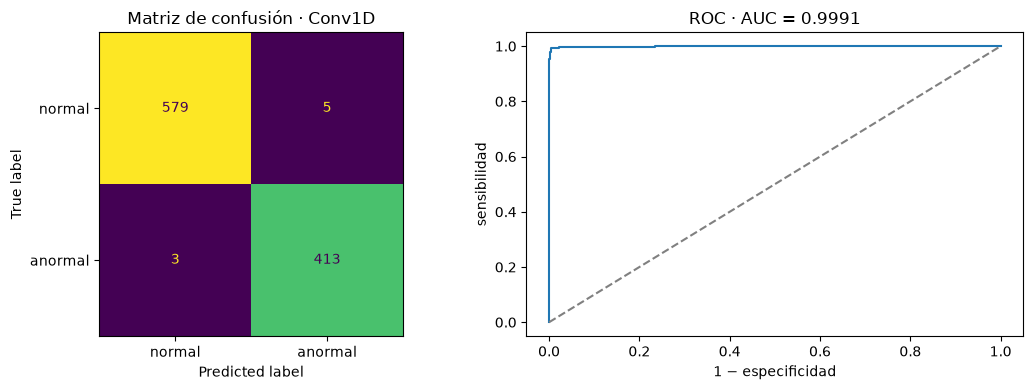

Guardado en modelo/modelo_ecg.keras y verificado.
Falsos negativos: 3 | Falsos positivos: 5


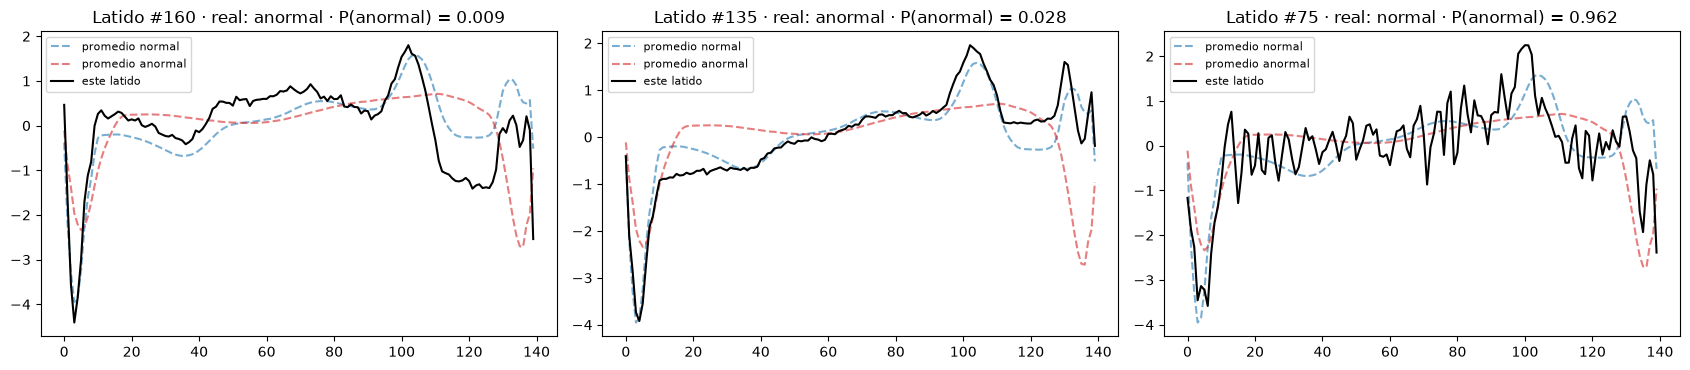

In [ ]:
p = prob_prueba[nombre_elegido]
pred = (p >= 0.5).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_prueba, pred), display_labels=["normal", "anormal"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title(f"Matriz de confusión · {nombre_elegido}")
fpr, tpr, _ = roc_curve(y_prueba, p)
ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_title(f"ROC · AUC = {roc_auc_score(y_prueba, p):.4f}"); ax[1].set_xlabel("1 − especificidad"); ax[1].set_ylabel("sensibilidad")
plt.tight_layout(); plt.show()

# Guardar el modelo elegido y comprobar que se recarga igual
os.makedirs("modelo", exist_ok=True)
modelos[nombre_elegido].save("modelo/modelo_ecg.keras")
recargado = keras.models.load_model("modelo/modelo_ecg.keras")
assert np.allclose(predecir(recargado, X_prueba3), p, atol=1e-5)
print("Guardado en modelo/modelo_ecg.keras y verificado.")

# Errores: falsos negativos (anormal no marcado) y falsos positivos (normal marcado)
fn = np.where((y_prueba == 1) & (pred == 0))[0]
fp = np.where((y_prueba == 0) & (pred == 1))[0]
print(f"Falsos negativos: {len(fn)} | Falsos positivos: {len(fp)}")

# Los 3 errores más "seguros" (más lejos del umbral). Si hay menos de 3, se completan con los casos más dudosos.
errores = sorted(list(fn) + list(fp), key=lambda i: -abs(p[i] - 0.5))[:3]
if len(errores) < 3:
    dudosos = [i for i in np.argsort(np.abs(p - 0.5)) if i not in errores]
    errores += dudosos[:3 - len(errores)]

media_n, media_a = X_resto[y_resto == 0].mean(0), X_resto[y_resto == 1].mean(0)
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
for a, i in zip(ax, errores):
    a.plot(t, media_n, "--", color="tab:blue", alpha=0.6, label="promedio normal")
    a.plot(t, media_a, "--", color="tab:red", alpha=0.6, label="promedio anormal")
    a.plot(t, X_prueba[i], color="black", label="este latido")
    real = "anormal" if y_prueba[i] == 1 else "normal"
    a.set_title(f"Latido #{i} · real: {real} · P(anormal) = {p[i]:.3f}")
    a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## ¿Por qué la Conv1D?
La elegimos con la validación, antes de ver la prueba. Las tres redes cumplían el 95 %, así que nos quedamos
con la que tenía más margen en su peor métrica: la Conv1D (98.2 % de sensibilidad, contra 97.6 % de la GRU
y 97.9 % del conjunto). Nos importa más la sensibilidad, porque un latido anormal que no se marca nunca lo
ve el cardiólogo. Además usa solo 5,857 parámetros (29 % del límite).

En la prueba: sensibilidad 99.3 % y especificidad 99.1 %, así que cumple. La GRU y el conjunto salieron un
poco mejor en especificidad en la prueba, pero no cambiamos la elección porque eso sería elegir con la prueba.

## Análisis de 3 errores
1. **#160, anormal, P = 0.009:** casi toda la señal se parece a un latido normal; solo cambia el final
   (después del punto 110 se queda abajo). El modelo no le da suficiente peso a esa parte.
2. **#135, anormal, P = 0.028:** se ve prácticamente igual al promedio normal. Puede ser una anomalía de
   ritmo (un latido adelantado), que no se ve viendo un solo latido, o un error de etiqueta.
3. **#75, normal, P = 0.962:** tiene la forma normal pero con mucho ruido. El modelo confunde el ruido con
   una anomalía; en un Holter real, con movimiento del paciente, esto daría falsas alarmas.

## ¿Con qué pacientes funcionaría?
Todos los datos son de un solo paciente con insuficiencia cardiaca, así que el 99 % solo dice que funciona
con nuevos latidos de ese paciente. Para usarlo con otras personas habría que probarlo con datos de muchos
pacientes (por ejemplo MIT-BIH), separando pacientes entre entrenamiento y prueba.